In [ ]:
#To be copied into each notebook
#imports necessary libraries, connects to google drive COSC74 Project file, defines features, and creates helper methods
import os, re, gc
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import time

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import ComplementNB, MultinomialNB
from sklearn.svm import LinearSVC
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, average_precision_score, confusion_matrix,
                             roc_curve, precision_recall_curve, classification_report)
from statsmodels.stats.proportion import proportion_confint

from google.colab import drive
drive.mount("/content/drive")

# File locations in Drive
PROJECT_DIR = "/content/drive/MyDrive/COSC74_project"
SUBSET_PATH = f"{PROJECT_DIR}/identity_subset.parquet"     # saved by the Step 1 notebook
SPLITS_PATH = f"{PROJECT_DIR}/splits.csv"                   # saved by the Step 2 notebook
VECTORIZER_PATH = f"{PROJECT_DIR}/tfidf_vectorizer.joblib"  # saved by the Step 2 notebook
RESULTS_DIR = f"{PROJECT_DIR}/results"   # tuned models, thresholds, validation results (Step 3+)
os.makedirs(RESULTS_DIR, exist_ok=True)

SEED = 42
IDENTITY_CATEGORIES = {
    "gender":             ["male", "female", "transgender", "other_gender"],
    "sexual_orientation": ["heterosexual", "homosexual_gay_or_lesbian", "bisexual",
                           "other_sexual_orientation"],
    "religion":           ["christian", "jewish", "muslim", "hindu", "buddhist", "atheist",
                           "other_religion"],
    "race_ethnicity":     ["black", "white", "asian", "latino", "other_race_or_ethnicity"],
    "disability":         ["physical_disability", "intellectual_or_learning_disability",
                           "psychiatric_or_mental_illness", "other_disability"],
}
IDENTITY_COLS = [c for cols in IDENTITY_CATEGORIES.values() for c in cols]
MENTION_COLS = [f"{c}_mentioned" for c in IDENTITY_COLS]
CATEGORY_COLS = [f"{cat}_mentioned" for cat in IDENTITY_CATEGORIES]

def load_data(with_splits=True):
    """Load the identity subset; if with_splits, attach each comment's train/val/test split."""
    data = pd.read_parquet(SUBSET_PATH)
    if with_splits:
        splits = pd.read_csv(SPLITS_PATH)
        data = data.merge(splits, on="id", how="inner")   # keeps only comments that were split
    return data

def get_scores(model, X):
    """Probability of toxic for LR/NB; signed distance from the boundary for LinearSVC."""
    if hasattr(model, "predict_proba"):
        return model.predict_proba(X)[:, 1]
    return model.decision_function(X)

def best_f1_threshold(y_true, scores):
    """Threshold that maximizes F1. Only ever call this on validation data."""
    precision, recall, thresholds = precision_recall_curve(y_true, scores)
    f1 = 2 * precision * recall / np.clip(precision + recall, 1e-12, None)
    best = np.argmax(f1[:-1])   # the last precision/recall pair has no threshold
    return thresholds[best], f1[best]

def evaluate(y_true, scores, threshold):
    """ROC-AUC and PR-AUC (no threshold needed) plus accuracy, precision, recall, F1 at a threshold."""
    preds = (scores >= threshold).astype(int)
    return {"roc_auc": roc_auc_score(y_true, scores),
            "pr_auc": average_precision_score(y_true, scores),
            "threshold": threshold,
            "accuracy": accuracy_score(y_true, preds),
            "precision": precision_score(y_true, preds, zero_division=0),
            "recall": recall_score(y_true, preds, zero_division=0),
            "f1": f1_score(y_true, preds, zero_division=0)}

np.random.seed(SEED)
pd.set_option("display.max_columns", 60)
print("Files in project folder:", os.listdir(PROJECT_DIR))

Mounted at /content/drive
Files in project folder: ['all_data.csv', 'identity_individual_annotations.csv', 'sample_submission.csv', 'test.csv', 'test_private_expanded.csv', 'test_public_expanded.csv', 'toxicity_individual_annotations.csv', 'train.csv', 'identity_subset.parquet', 'splits.csv', 'tfidf_vectorizer.joblib', 'results']




```
# This is formatted as code
```

**Majority class baseline**

In [ ]:
# Load the data with the train/validation/test splits
df = load_data(with_splits=True)

# Separate training and validation data
train_df = df[df["split"] == "train"]
val_df = df[df["split"] == "val"]

# Separate comment text (X) and toxicity labels (y)
X_train = train_df["comment_text"]
y_train = train_df["toxic"]

X_val = val_df["comment_text"]
y_val = val_df["toxic"]

print(f"Training comments: {len(X_train):,}")
print(f"Validation comments: {len(X_val):,}")

Training comments: 281,404
Validation comments: 80,401


In [ ]:
# Load the TF-IDF vectorizer saved in Part 2
vectorizer = joblib.load(VECTORIZER_PATH)

# Convert comments into numerical features
X_train_vec = vectorizer.transform(X_train)
X_val_vec = vectorizer.transform(X_val)

print("Training shape:", X_train_vec.shape)
print("Validation shape:", X_val_vec.shape)

Training shape: (281404, 200000)
Validation shape: (80401, 200000)


In [ ]:
# Majority-class baseline
baseline = DummyClassifier(strategy="most_frequent")

# Fit on training data
baseline.fit(X_train_vec, y_train)

# Predict on validation data
y_val_pred_baseline = baseline.predict(X_val_vec)

print("Majority class:", baseline.classes_[np.argmax(baseline.class_prior_)])
print("Predicted classes:", np.unique(y_val_pred_baseline))

Majority class: 0
Predicted classes: [0]


In [ ]:
# Calculate evaluation metrics
baseline_accuracy = accuracy_score(y_val, y_val_pred_baseline)
baseline_precision = precision_score(y_val, y_val_pred_baseline, zero_division=0)
baseline_recall = recall_score(y_val, y_val_pred_baseline, zero_division=0)
baseline_f1 = f1_score(y_val, y_val_pred_baseline, zero_division=0)

# Get predicted probabilities for the toxic class
baseline_scores = baseline.predict_proba(X_val_vec)[:, 1]

# Calculate AUC metrics
baseline_roc_auc = roc_auc_score(y_val, baseline_scores)
baseline_pr_auc = average_precision_score(y_val, baseline_scores)

print(f"Accuracy:  {baseline_accuracy:.4f}")
print(f"Precision: {baseline_precision:.4f}")
print(f"Recall:    {baseline_recall:.4f}")
print(f"F1 Score:  {baseline_f1:.4f}")
print(f"ROC-AUC:   {baseline_roc_auc:.4f}")
print(f"PR-AUC:    {baseline_pr_auc:.4f}")

Accuracy:  0.8864
Precision: 0.0000
Recall:    0.0000
F1 Score:  0.0000
ROC-AUC:   0.5000
PR-AUC:    0.1136


Confusion Matrix:
[[71270     0]
 [ 9131     0]]


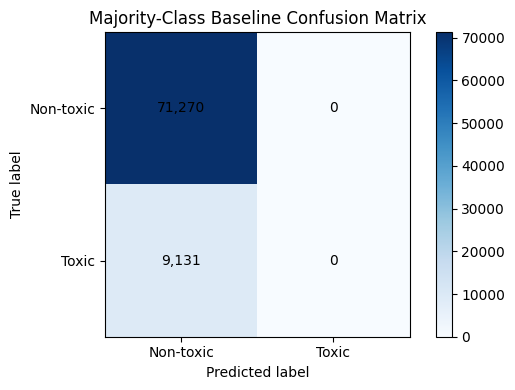

In [ ]:
 # Confusion matrix
cm = confusion_matrix(y_val, y_val_pred_baseline)

print("Confusion Matrix:")
print(cm)

plt.figure(figsize=(6, 4))
plt.imshow(cm, cmap="Blues")
plt.colorbar()

plt.xticks([0, 1], ["Non-toxic", "Toxic"])
plt.yticks([0, 1], ["Non-toxic", "Toxic"])

plt.xlabel("Predicted label")
plt.ylabel("True label")
plt.title("Majority-Class Baseline Confusion Matrix")

for i in range(2):
    for j in range(2):
        plt.text(j, i, f"{cm[i, j]:,}",
                 ha="center", va="center")

plt.tight_layout()
plt.show()

In [ ]:
# Store baseline results
baseline_results = pd.DataFrame([{
    "model": "Majority Class",
    "accuracy": baseline_accuracy,
    "precision": baseline_precision,
    "recall": baseline_recall,
    "f1": baseline_f1,
    "roc_auc": baseline_roc_auc,
    "pr_auc": baseline_pr_auc
}])

display(baseline_results)

# Save to shared Google Drive
baseline_results.to_csv(f"{RESULTS_DIR}/baseline_results.csv", index=False)

,model,accuracy,precision,recall,f1,roc_auc,pr_auc
0,Majority Class,0.886432,0.0,0.0,0.0,0.5,0.113568


**Logistic Regression**

In [ ]:
#tune c and class weight
C_VALUES = [0.01, 0.1, 1, 10]
CLASS_WEIGHTS = [None, "balanced"]

lr_results = []
lr_models = {}
lr_val_scores_by_config = {}

for class_weight in CLASS_WEIGHTS:
    for C in C_VALUES:
        config = f"C={C}, class_weight={class_weight}"
        start = time.time()
        model = LogisticRegression(C=C, class_weight=class_weight, solver="liblinear",
                                   max_iter=1000, random_state=SEED)
        model.fit(X_train_vec, y_train)
        fit_seconds = time.time() - start

        val_scores = get_scores(model, X_val_vec)
        threshold, _ = best_f1_threshold(y_val, val_scores)   # chosen on validation
        metrics = evaluate(y_val, val_scores, threshold)

        lr_models[config] = model
        lr_val_scores_by_config[config] = val_scores
        lr_results.append({"config": config, "C": C, "class_weight": str(class_weight),
                           **metrics, "fit_seconds": round(fit_seconds, 1)})
        print(f"{config:<32} PR-AUC={metrics['pr_auc']:.4f}  ROC-AUC={metrics['roc_auc']:.4f}  "
              f"F1={metrics['f1']:.4f}  ({fit_seconds:.0f}s)")

C=0.01, class_weight=None        PR-AUC=0.4083  ROC-AUC=0.8244  F1=0.4483  (4s)
C=0.1, class_weight=None         PR-AUC=0.5394  ROC-AUC=0.8775  F1=0.5323  (8s)
C=1, class_weight=None           PR-AUC=0.6508  ROC-AUC=0.9139  F1=0.5992  (12s)
C=10, class_weight=None          PR-AUC=0.6453  ROC-AUC=0.9040  F1=0.5949  (23s)
C=0.01, class_weight=balanced    PR-AUC=0.4413  ROC-AUC=0.8407  F1=0.4682  (5s)
C=0.1, class_weight=balanced     PR-AUC=0.5724  ROC-AUC=0.8921  F1=0.5544  (8s)
C=1, class_weight=balanced       PR-AUC=0.6489  ROC-AUC=0.9144  F1=0.6001  (19s)
C=10, class_weight=balanced      PR-AUC=0.6403  ROC-AUC=0.9017  F1=0.5902  (39s)


,C,class_weight,roc_auc,pr_auc,threshold,accuracy,precision,recall,f1,fit_seconds
0,1.00,None,0.9139,0.6508,0.2185,0.9022,0.5603,0.6440,0.5992,12.3
1,1.00,balanced,0.9144,0.6489,0.6515,0.9079,0.5923,0.6081,0.6001,19.1
2,10.00,None,0.9040,0.6453,0.2659,0.9062,0.5835,0.6068,0.5949,23.4
3,10.00,balanced,0.9017,0.6403,0.5855,0.9045,0.5757,0.6054,0.5902,39.4
4,0.10,balanced,0.8921,0.5724,0.5837,0.8874,0.5036,0.6166,0.5544,8.5
5,0.10,None,0.8775,0.5394,0.1749,0.8832,0.4881,0.5854,0.5323,8.2
6,0.01,balanced,0.8407,0.4413,0.5358,0.8640,0.4211,0.5272,0.4682,4.8
7,0.01,None,0.8244,0.4083,0.1300,0.8560,0.3967,0.5154,0.4483,4.2


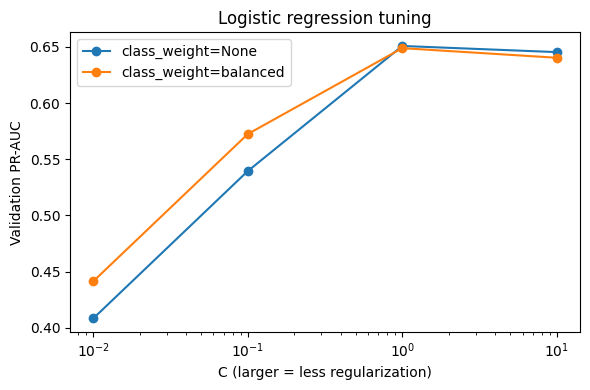

In [ ]:
lr_results = pd.DataFrame(lr_results).sort_values("pr_auc", ascending=False).reset_index(drop=True)
display(lr_results.drop(columns="config").round(4))

fig, ax = plt.subplots(figsize=(6, 4))
for cw, group in lr_results.groupby("class_weight"):
    group = group.sort_values("C")
    ax.plot(group["C"], group["pr_auc"], marker="o", label=f"class_weight={cw}")
ax.set_xscale("log")
ax.set_xlabel("C (larger = less regularization)")
ax.set_ylabel("Validation PR-AUC")
ax.set_title("Logistic regression tuning")
ax.legend()
plt.tight_layout()
plt.show()

In [ ]:
best = lr_results.iloc[0]
lr_best = lr_models[best["config"]]
lr_threshold = best["threshold"]
lr_val_scores = lr_val_scores_by_config[best["config"]]
print(f"Best logistic regression: {best['config']}, threshold = {lr_threshold:.3f}")

lr_at_threshold = evaluate(y_val, lr_val_scores, lr_threshold)
lr_at_default = evaluate(y_val, lr_val_scores, 0.5)
display(pd.DataFrame({f"chosen threshold ({lr_threshold:.3f})": lr_at_threshold,
                      "default threshold (0.5)": lr_at_default}).T.round(4))

Best logistic regression: C=1, class_weight=None, threshold = 0.219


,roc_auc,pr_auc,threshold,accuracy,precision,recall,f1
chosen threshold (0.219),0.9139,0.6508,0.2185,0.9022,0.5603,0.6440,0.5992
default threshold (0.5),0.9139,0.6508,0.5000,0.9128,0.8022,0.3077,0.4448


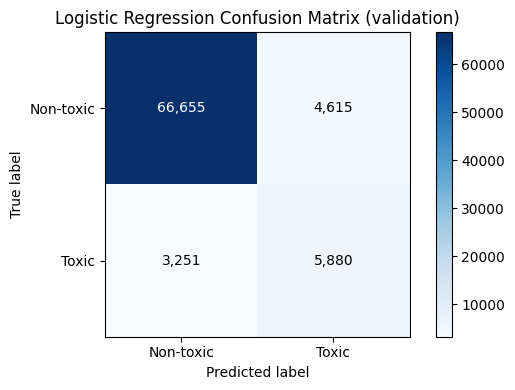

In [ ]:
cm = confusion_matrix(y_val, (lr_val_scores >= lr_threshold).astype(int))

plt.figure(figsize=(6, 4))
plt.imshow(cm, cmap="Blues")
plt.colorbar()
plt.xticks([0, 1], ["Non-toxic", "Toxic"])
plt.yticks([0, 1], ["Non-toxic", "Toxic"])
plt.xlabel("Predicted label")
plt.ylabel("True label")
plt.title("Logistic Regression Confusion Matrix (validation)")
for i in range(2):
    for j in range(2):
        plt.text(j, i, f"{cm[i, j]:,}", ha="center", va="center",
                 color="white" if cm[i, j] > cm.max() / 2 else "black")
plt.tight_layout()
plt.show()

In [ ]:
# Every configuration tried, for the report
lr_results.drop(columns="config").to_csv(f"{RESULTS_DIR}/lr_tuning_results.csv", index=False)

# The best model and its threshold, for the bias analysis and final test
joblib.dump({"model": lr_best, "threshold": lr_threshold, "config": best["config"]},
            f"{RESULTS_DIR}/lr_best.joblib")

# One row in the same format as baseline_results, so all models can be combined later
lr_summary = pd.DataFrame([{"model": "Logistic Regression",
                            **{k: lr_at_threshold[k] for k in
                               ["accuracy", "precision", "recall", "f1", "roc_auc", "pr_auc"]},
                            "threshold": lr_threshold, "config": best["config"]}])
lr_summary.to_csv(f"{RESULTS_DIR}/lr_results.csv", index=False)
display(lr_summary)

,model,accuracy,precision,recall,f1,roc_auc,pr_auc,threshold,config
0,Logistic Regression,0.902165,0.560267,0.64396,0.599205,0.913933,0.650805,0.218528,"C=1, class_weight=None"


**Naive Bayes**

In [ ]:
# Tune alpha for ComplementNB and MultinomialNB
ALPHA_VALUES = [0.01, 0.1, 0.5, 1]

NB_MODELS = {
    "ComplementNB": ComplementNB,
    "MultinomialNB": MultinomialNB
}

nb_results = []
nb_models = {}
nb_val_scores_by_config = {}

for model_name, model_class in NB_MODELS.items():
    for alpha in ALPHA_VALUES:
        config = f"{model_name}, alpha={alpha}"
        start = time.time()

        model = model_class(alpha=alpha)
        model.fit(X_train_vec, y_train)
        fit_seconds = time.time() - start

        # Get predicted probabilities on validation data
        val_scores = get_scores(model, X_val_vec)

        # Choose threshold that maximizes F1 on validation
        threshold, _ = best_f1_threshold(y_val, val_scores)

        # Evaluate using the chosen threshold
        metrics = evaluate(y_val, val_scores, threshold)

        # Save models, scores, and results
        nb_models[config] = model
        nb_val_scores_by_config[config] = val_scores

        nb_results.append({
            "config": config,
            "model_type": model_name,
            "alpha": alpha,
            **metrics,
            "fit_seconds": round(fit_seconds, 1)
        })

        print(f"{config:<35} "
              f"PR-AUC={metrics['pr_auc']:.4f} "
              f"ROC-AUC={metrics['roc_auc']:.4f} "
              f"F1={metrics['f1']:.4f} "
              f"({fit_seconds:.0f}s)")

ComplementNB, alpha=0.01            PR-AUC=0.4737 ROC-AUC=0.8219 F1=0.4811 (0s)
ComplementNB, alpha=0.1             PR-AUC=0.5032 ROC-AUC=0.8482 F1=0.5082 (1s)
ComplementNB, alpha=0.5             PR-AUC=0.4933 ROC-AUC=0.8423 F1=0.4935 (1s)
ComplementNB, alpha=1               PR-AUC=0.4358 ROC-AUC=0.8064 F1=0.4419 (1s)
MultinomialNB, alpha=0.01           PR-AUC=0.4737 ROC-AUC=0.8219 F1=0.4811 (0s)
MultinomialNB, alpha=0.1            PR-AUC=0.5032 ROC-AUC=0.8482 F1=0.5082 (0s)
MultinomialNB, alpha=0.5            PR-AUC=0.4933 ROC-AUC=0.8423 F1=0.4935 (0s)
MultinomialNB, alpha=1              PR-AUC=0.4358 ROC-AUC=0.8064 F1=0.4419 (0s)


,model_type,alpha,roc_auc,pr_auc,threshold,accuracy,precision,recall,f1,fit_seconds
0,ComplementNB,0.10,0.8482,0.5032,0.6739,0.8808,0.4783,0.5422,0.5082,0.5
1,MultinomialNB,0.10,0.8482,0.5032,0.2093,0.8808,0.4783,0.5422,0.5082,0.2
2,MultinomialNB,0.50,0.8423,0.4933,0.1441,0.8751,0.4575,0.5356,0.4935,0.2
3,ComplementNB,0.50,0.8423,0.4933,0.5679,0.8751,0.4575,0.5356,0.4935,0.5
4,MultinomialNB,0.01,0.8219,0.4737,0.2089,0.8782,0.4660,0.4973,0.4811,0.2
5,ComplementNB,0.01,0.8219,0.4737,0.6733,0.8782,0.4660,0.4973,0.4811,0.5
6,MultinomialNB,1.00,0.8064,0.4358,0.0896,0.8604,0.4047,0.4867,0.4419,0.2
7,ComplementNB,1.00,0.8064,0.4358,0.4344,0.8604,0.4047,0.4867,0.4419,0.6


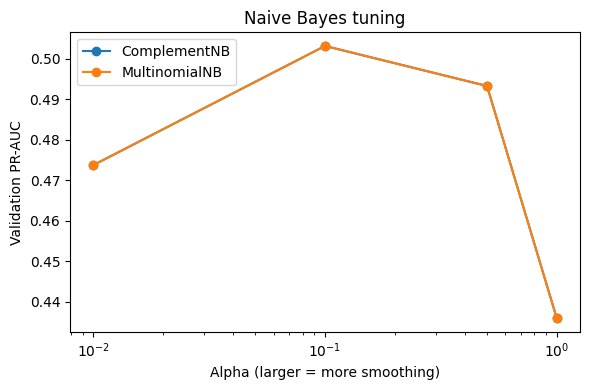

In [ ]:
nb_results = (pd.DataFrame(nb_results)
              .sort_values("pr_auc", ascending=False)
              .reset_index(drop=True))

display(nb_results.drop(columns="config").round(4))

fig, ax = plt.subplots(figsize=(6, 4))

for model_name, group in nb_results.groupby("model_type"):
    group = group.sort_values("alpha")
    ax.plot(group["alpha"], group["pr_auc"],
            marker="o", label=model_name)

ax.set_xscale("log")
ax.set_xlabel("Alpha (larger = more smoothing)")
ax.set_ylabel("Validation PR-AUC")
ax.set_title("Naive Bayes tuning")
ax.legend()

plt.tight_layout()
plt.show()

In [ ]:
best = nb_results.iloc[0]

nb_best = nb_models[best["config"]]
nb_threshold = best["threshold"]
nb_val_scores = nb_val_scores_by_config[best["config"]]

print(f"Best Naive Bayes: {best['config']}, "
      f"threshold = {nb_threshold:.3f}")

# Compare chosen threshold against default 0.5
nb_at_threshold = evaluate(y_val, nb_val_scores, nb_threshold)
nb_at_default = evaluate(y_val, nb_val_scores, 0.5)

display(pd.DataFrame({
    f"chosen threshold ({nb_threshold:.3f})": nb_at_threshold,
    "default threshold (0.5)": nb_at_default
}).T.round(4))

Best Naive Bayes: ComplementNB, alpha=0.1, threshold = 0.674


,roc_auc,pr_auc,threshold,accuracy,precision,recall,f1
chosen threshold (0.674),0.8482,0.5032,0.6739,0.8808,0.4783,0.5422,0.5082
default threshold (0.5),0.8482,0.5032,0.5000,0.7874,0.3152,0.7437,0.4428


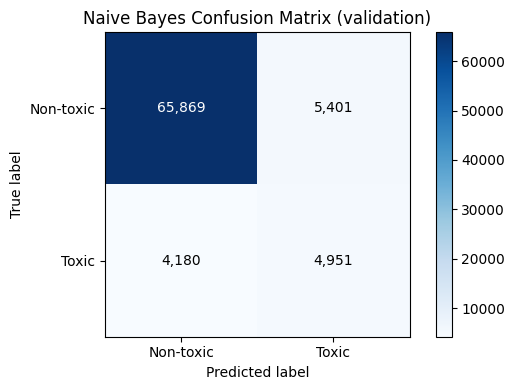

In [ ]:
cm = confusion_matrix(
    y_val,
    (nb_val_scores >= nb_threshold).astype(int)
)

plt.figure(figsize=(6, 4))
plt.imshow(cm, cmap="Blues")
plt.colorbar()

plt.xticks([0, 1], ["Non-toxic", "Toxic"])
plt.yticks([0, 1], ["Non-toxic", "Toxic"])

plt.xlabel("Predicted label")
plt.ylabel("True label")
plt.title("Naive Bayes Confusion Matrix (validation)")

for i in range(2):
    for j in range(2):
        plt.text(j, i, f"{cm[i, j]:,}",
                 ha="center", va="center",
                 color="white" if cm[i, j] > cm.max() / 2 else "black")

plt.tight_layout()
plt.show()

In [ ]:
# Every configuration tried, for the report
nb_results.drop(columns="config").to_csv(
    f"{RESULTS_DIR}/nb_tuning_results.csv",
    index=False
)

# Save best model and threshold
joblib.dump({
    "model": nb_best,
    "threshold": nb_threshold,
    "config": best["config"]
}, f"{RESULTS_DIR}/nb_best.joblib")

# Summary in same format as Logistic Regression
nb_summary = pd.DataFrame([{
    "model": "Naive Bayes",
    **{k: nb_at_threshold[k] for k in
       ["accuracy", "precision", "recall", "f1",
        "roc_auc", "pr_auc"]},
    "threshold": nb_threshold,
    "config": best["config"]
}])

nb_summary.to_csv(
    f"{RESULTS_DIR}/nb_results.csv",
    index=False
)

display(nb_summary)

,model,accuracy,precision,recall,f1,roc_auc,pr_auc,threshold,config
0,Naive Bayes,0.880835,0.478265,0.542219,0.508238,0.848151,0.503198,0.673892,"ComplementNB, alpha=0.1"


In [ ]:
#comparing naive bayes against logistic regression

lr_summary = pd.read_csv(f"{RESULTS_DIR}/lr_results.csv")
nb_summary = pd.read_csv(f"{RESULTS_DIR}/nb_results.csv")

comparison = pd.concat(
    [lr_summary, nb_summary],
    ignore_index=True
)

display(comparison.round(4))

,model,accuracy,precision,recall,f1,roc_auc,pr_auc,threshold,config
0,Logistic Regression,0.9022,0.5603,0.6440,0.5992,0.9139,0.6508,0.2185,"C=1, class_weight=None"
1,Naive Bayes,0.8808,0.4783,0.5422,0.5082,0.8482,0.5032,0.6739,"ComplementNB, alpha=0.1"


**Linear SVM**

In [ ]:
# Load the data and saved TF-IDF vectorizer
df = load_data(with_splits=True)

train_df = df[df["split"] == "train"]
val_df = df[df["split"] == "val"]

X_train = train_df["comment_text"]
y_train = train_df["toxic"]

X_val = val_df["comment_text"]
y_val = val_df["toxic"]

vectorizer = joblib.load(VECTORIZER_PATH)

X_train_vec = vectorizer.transform(X_train)
X_val_vec = vectorizer.transform(X_val)

print("Training:", X_train_vec.shape)
print("Validation:", X_val_vec.shape)

Training: (281404, 200000)
Validation: (80401, 200000)


In [ ]:
import time
from sklearn.svm import LinearSVC

# Tune C and class weight
C_VALUES = [0.01, 0.1, 1, 10]
CLASS_WEIGHTS = [None, "balanced"]

svm_results = []
svm_models = {}
svm_val_scores_by_config = {}

for class_weight in CLASS_WEIGHTS:
    for C in C_VALUES:

        config = f"C={C}, class_weight={class_weight}"
        start = time.time()

        # Create and train the model
        model = LinearSVC(
            C=C,
            class_weight=class_weight,
            max_iter=5000,
            random_state=SEED
        )

        model.fit(X_train_vec, y_train)
        fit_seconds = time.time() - start

        # Get validation decision scores
        val_scores = get_scores(model, X_val_vec)

        # Find threshold that maximizes F1
        threshold, _ = best_f1_threshold(y_val, val_scores)

        # Evaluate on validation data
        metrics = evaluate(y_val, val_scores, threshold)

        # Save results
        svm_models[config] = model
        svm_val_scores_by_config[config] = val_scores

        svm_results.append({
            "config": config,
            "C": C,
            "class_weight": str(class_weight),
            **metrics,
            "fit_seconds": round(fit_seconds, 1)
        })

        print(
            f"{config:<32} "
            f"PR-AUC={metrics['pr_auc']:.4f} "
            f"ROC-AUC={metrics['roc_auc']:.4f} "
            f"F1={metrics['f1']:.4f} "
            f"({fit_seconds:.0f}s)"
        )

C=0.01, class_weight=None        PR-AUC=0.5785 ROC-AUC=0.8947 F1=0.5583 (13s)
C=0.1, class_weight=None         PR-AUC=0.6682 ROC-AUC=0.9189 F1=0.6125 (14s)
C=1, class_weight=None           PR-AUC=0.6381 ROC-AUC=0.8963 F1=0.5914 (22s)
C=10, class_weight=None          PR-AUC=0.5645 ROC-AUC=0.8588 F1=0.5308 (41s)
C=0.01, class_weight=balanced    PR-AUC=0.5677 ROC-AUC=0.8909 F1=0.5513 (9s)
C=0.1, class_weight=balanced     PR-AUC=0.6482 ROC-AUC=0.9149 F1=0.6002 (18s)
C=1, class_weight=balanced       PR-AUC=0.6258 ROC-AUC=0.8940 F1=0.5798 (33s)
C=10, class_weight=balanced      PR-AUC=0.5644 ROC-AUC=0.8598 F1=0.5323 (114s)


,C,class_weight,roc_auc,pr_auc,threshold,accuracy,precision,recall,f1,fit_seconds
0,0.10,None,0.9189,0.6682,-0.4185,0.9099,0.5988,0.6268,0.6125,13.6
1,0.10,balanced,0.9149,0.6482,0.1614,0.9022,0.5603,0.6462,0.6002,17.7
2,1.00,None,0.8963,0.6381,-0.2885,0.9058,0.5831,0.5999,0.5914,22.0
3,1.00,balanced,0.8940,0.6258,0.1355,0.9038,0.5753,0.5844,0.5798,32.8
4,0.01,None,0.8947,0.5785,-0.5868,0.8907,0.5158,0.6085,0.5583,13.3
5,0.01,balanced,0.8909,0.5677,0.1371,0.8870,0.5021,0.6113,0.5513,8.8
6,10.00,None,0.8588,0.5645,-0.1425,0.8924,0.5257,0.5361,0.5308,41.4
7,10.00,balanced,0.8598,0.5644,-0.0171,0.8920,0.5238,0.5410,0.5323,114.3


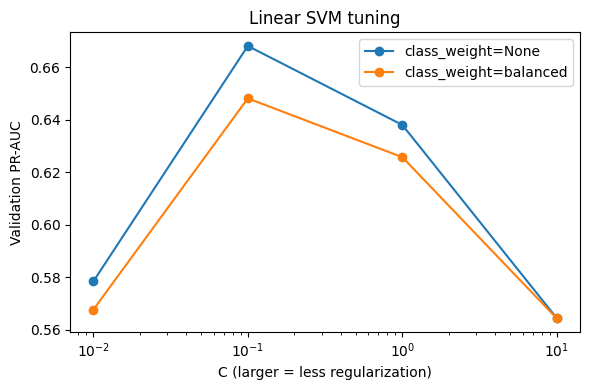

In [ ]:
svm_results = (
    pd.DataFrame(svm_results)
    .sort_values("pr_auc", ascending=False)
    .reset_index(drop=True)
)

display(svm_results.drop(columns="config").round(4))

# Plot C vs. PR-AUC
fig, ax = plt.subplots(figsize=(6, 4))

for cw, group in svm_results.groupby("class_weight"):
    group = group.sort_values("C")

    ax.plot(
        group["C"],
        group["pr_auc"],
        marker="o",
        label=f"class_weight={cw}"
    )

ax.set_xscale("log")
ax.set_xlabel("C (larger = less regularization)")
ax.set_ylabel("Validation PR-AUC")
ax.set_title("Linear SVM tuning")
ax.legend()

plt.tight_layout()
plt.show()

In [ ]:
# Select best model based on PR-AUC
best = svm_results.iloc[0]

svm_best = svm_models[best["config"]]
svm_threshold = best["threshold"]
svm_val_scores = svm_val_scores_by_config[best["config"]]

print(
    f"Best Linear SVM: {best['config']}, "
    f"threshold = {svm_threshold:.3f}"
)

# Evaluate at chosen and default thresholds
svm_at_threshold = evaluate(
    y_val, svm_val_scores, svm_threshold
)

svm_at_default = evaluate(
    y_val, svm_val_scores, 0.0
)

display(
    pd.DataFrame({
        f"chosen threshold ({svm_threshold:.3f})": svm_at_threshold,
        "default threshold (0)": svm_at_default
    }).T.round(4)
)

Best Linear SVM: C=0.1, class_weight=None, threshold = -0.419


,roc_auc,pr_auc,threshold,accuracy,precision,recall,f1
chosen threshold (-0.419),0.9189,0.6682,-0.4185,0.9099,0.5988,0.6268,0.6125
default threshold (0),0.9189,0.6682,0.0000,0.9127,0.8370,0.2874,0.4278


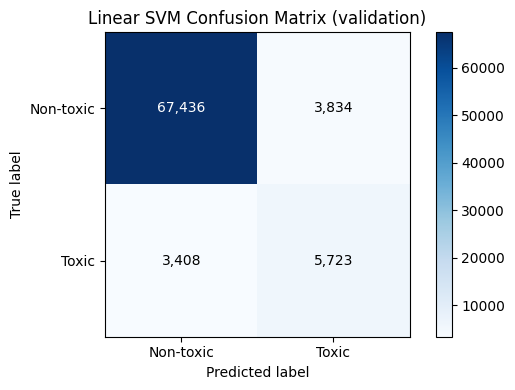

In [ ]:
# Predict using chosen threshold
svm_predictions = (
    svm_val_scores >= svm_threshold
).astype(int)

cm = confusion_matrix(y_val, svm_predictions)

plt.figure(figsize=(6, 4))
plt.imshow(cm, cmap="Blues")
plt.colorbar()

plt.xticks([0, 1], ["Non-toxic", "Toxic"])
plt.yticks([0, 1], ["Non-toxic", "Toxic"])

plt.xlabel("Predicted label")
plt.ylabel("True label")
plt.title("Linear SVM Confusion Matrix (validation)")

for i in range(2):
    for j in range(2):
        plt.text(
            j, i, f"{cm[i, j]:,}",
            ha="center",
            va="center",
            color="white" if cm[i, j] > cm.max() / 2 else "black"
        )

plt.tight_layout()
plt.show()

In [ ]:
# Save every configuration tested
svm_results.drop(columns="config").to_csv(
    f"{RESULTS_DIR}/svm_tuning_results.csv",
    index=False
)

# Save best SVM model and chosen threshold
joblib.dump(
    {
        "model": svm_best,
        "threshold": svm_threshold,
        "config": best["config"]
    },
    f"{RESULTS_DIR}/svm_best.joblib"
)

# Save summary in same format as other models
svm_summary = pd.DataFrame([{
    "model": "Linear SVM",
    **{k: svm_at_threshold[k] for k in
       ["accuracy", "precision", "recall", "f1",
        "roc_auc", "pr_auc"]},
    "threshold": svm_threshold,
    "config": best["config"]
}])

svm_summary.to_csv(
    f"{RESULTS_DIR}/svm_results.csv",
    index=False
)

display(svm_summary)

,model,accuracy,precision,recall,f1,roc_auc,pr_auc,threshold,config
0,Linear SVM,0.909926,0.598828,0.626766,0.612479,0.918876,0.668182,-0.418506,"C=0.1, class_weight=None"


In [ ]:
# Load model summaries
baseline_results = pd.read_csv(
    f"{RESULTS_DIR}/baseline_results.csv"
)

lr_results = pd.read_csv(
    f"{RESULTS_DIR}/lr_results.csv"
)

nb_results = pd.read_csv(
    f"{RESULTS_DIR}/nb_results.csv"
)

svm_results_final = pd.read_csv(
    f"{RESULTS_DIR}/svm_results.csv"
)

# Combine results
all_results = pd.concat([
    baseline_results,
    lr_results,
    nb_results,
    svm_results_final
], ignore_index=True)

# Sort by PR-AUC
all_results = all_results.sort_values(
    "pr_auc", ascending=False
)

display(all_results.round(4))

,model,accuracy,precision,recall,f1,roc_auc,pr_auc,threshold,config
3,Linear SVM,0.9099,0.5988,0.6268,0.6125,0.9189,0.6682,-0.4185,"C=0.1, class_weight=None"
1,Logistic Regression,0.9022,0.5603,0.6440,0.5992,0.9139,0.6508,0.2185,"C=1, class_weight=None"
2,Naive Bayes,0.8808,0.4783,0.5422,0.5082,0.8482,0.5032,0.6739,"ComplementNB, alpha=0.1"
0,Majority Class,0.8864,0.0000,0.0000,0.0000,0.5000,0.1136,NaN,NaN
